# Story: PSCA arms NK cells, RT lifts the local brake, and a two-cell macrophage adenosine relay remains

Five presentation figures. Everything is recomputed here from the pseudobulks and from the outputs of
`mhcCytotoxExhaustion/07_adenosine_signaling_sc`, `specificCellTypeAnalysis/01_macrophage_rt` and
`specificCellTypeAnalysis/03_nk_rt`.

| figure | message | strength |
|---|---|---|
| **1** | PSCA CAR-T arms NK cells in the **abscopal** tumor: granzymes, CCL5/CCL3, IFN-γ | shown (exact p 0.005–0.02) |
| **2** | In the **irradiated** tumor, RT + PSCA lifts the local brake: CD73 down, PGE2 down, Cxcl16 up, NK interferon response up, fewer NKG2A+ NK | the local RT story |
| **3** | The adenosine machine is a **two-cell macrophage relay**: TREM2+/SPP1-TAMs run CD38 → CD203a, a different TAM subset finishes with CD73 | shown |
| **4** | The abscopal tumor keeps the brake: CD73 persists, ~32% of NK carry A2A, Tregs rise; more myeloid CD73 goes with less armed NK | shown + association |
| **5** | Model and the proposed experiments | hypothesis |

### Design and statistics
* Arms: CyPSCA, CyT72 (TAG72 = non-specific CAR), RTCyPSCA, RTCyT72; **Tu1** is the irradiated tumor in RT
  mice and the site-matched tumor in no-RT mice, **Tu2** the abscopal one. Unit = one tumor.
* **PSCA effect** = PSCA − TAG72 within an RT stratum; **pooled** averages the two strata.
  **RT in PSCA / in TAG72** = RT − no RT within one CAR; **CAR × RT** = the difference between them.
* **p-values:** exact relabelling for pooled and CAR × RT; Welch t within one CAR, where the exact floor is
  0.10 at 3 v 3. Nominal, no correction across figures.
* **NK counts are small** (5–107 cells per tumor); NK readouts use tumors with ≥ 5 NK cells and dot size shows
  the count.
* **What is not measured:** adenosine itself, protein, and any causal step. Figure 4C is an association across
  tumors of the same arm and site.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import itertools, json
from pathlib import Path
import numpy as np, pandas as pd
from scipy import stats
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from matplotlib.gridspec import GridSpec

_HPC = Path("/coh_labs/yunroseli/Jona/CAR-T"); _LOC = Path("/Users/janzules/Roselab/Spatial/CAR_T")
PROJ = _LOC if _LOC.exists() else _HPC
SRC = PROJ/"results/mhc_cytotox"; ADE = SRC/"07_adenosine"
NKD = PROJ/"results/rt_advantage/specific_cell_type/nk"
MACD = PROJ/"results/rt_advantage/specific_cell_type/macrophages"
OUT = PROJ/"results/rt_advantage/specific_cell_type/story"; OUT.mkdir(parents=True, exist_ok=True)
for f_ in [SRC/"pseudobulk_counts.parquet", SRC/"cell_panel.parquet", ADE/"07_ectoenzyme_pool_shares.csv",
           ADE/"07_fig6D_receptor_detection.csv", NKD/"nk_fractions_per_tumor.csv", NKD/"nk_gsea_hallmark.parquet",
           NKD/"nk_phenotype_effects.csv", NKD/"nk_recruitment_effects.csv", NKD/"spatial_lymphocyte_census_per_tumor.csv",
           MACD/"de_state_vs_rest.parquet", MACD/"module_effects.csv"]:
    assert Path(f_).exists(), f"missing {f_}"
SEED = 0

INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
C_PSCA, C_TAG72, C_NOTX = "#eb6834", "#2a78d6", "#898781"
S_GOOD, S_WARN, S_CRIT = "#0ca30c", "#fab219", "#d03b3b"
VIOLET, VIOLET_L, TEAL = "#5342ba", "#b6b7f3", "#1c7c74"
DIVC = mpl.colors.LinearSegmentedColormap.from_list("div", ["#104281", "#1c5cab", "#3987e5", "#86b6ef", "#cde2fb",
                                                            "#f0efec", "#fad6d2", "#ea9a93", "#d75853", "#9e3432", "#762221"])
SEQC = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#d9dbfc", "#b6b7f3", "#918fe9", "#7067da", "#5342ba",
                                                            "#382887", "#231859"])
mpl.rcParams.update({
    "font.family": ["Arial", "DejaVu Sans"], "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 8.8, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white", "axes.facecolor": "white",
    "savefig.facecolor": "white", "pdf.fonttype": 42, "ps.fonttype": 42, "savefig.dpi": 300, "text.color": INK})

ARMS4 = ["CyPSCA", "RTCyPSCA", "CyT72", "RTCyT72"]
ARM_SHORT = {"CyPSCA": "PSCA", "RTCyPSCA": "PSCA\n+ RT", "CyT72": "TAG72", "RTCyT72": "TAG72\n+ RT", "NoTx": "untreated"}
CAR_OF = {"CyPSCA": "PSCA", "RTCyPSCA": "PSCA", "CyT72": "TAG72", "RTCyT72": "TAG72", "NoTx": "none"}
RT_OF = {"CyPSCA": False, "RTCyPSCA": True, "CyT72": False, "RTCyT72": True, "NoTx": False}
CAR_COL = {"PSCA": C_PSCA, "TAG72": C_TAG72, "none": C_NOTX}


def norm_arm(a): return str(a).replace("TAG72", "T72")


def fmt_p(p):
    if p is None or not np.isfinite(p): return "n/a"
    return "<0.001" if p < 0.001 else (f"{p:.3f}" if p < 0.1 else f"{p:.2f}")


def sample_meta(samples):
    s = pd.Series(list(samples), index=list(samples))
    p = s.str.extract(r"^(?P<arm>.+)_Tu(?P<site>\d)_(?P<rep>\d+)$")
    return pd.DataFrame({"arm": p.arm.map(norm_arm).values, "site": p.site.astype(int).values,
                         "mouse": (p.arm.map(norm_arm) + "_m" + p.rep).values}, index=s.index)


# ---- exact-relabelling engine (same definitions as notebooks 01 and 03) ----
def _cell(v, meta, A, B, site):
    idx = [i for i in meta.index[meta.arm.isin([A, B]) & (meta.site == site)] if np.isfinite(v.get(i, np.nan))]
    a = v[[i for i in idx if meta.loc[i, "arm"] == A]]; b = v[[i for i in idx if meta.loc[i, "arm"] == B]]
    if len(a) < 2 or len(b) < 2: return None
    x = np.r_[a.values, b.values]; k = len(a); null = [a.mean() - b.mean()]
    for c in itertools.combinations(range(len(x)), k):
        if c == tuple(range(k)): continue
        m = np.isin(np.arange(len(x)), c); null.append(x[m].mean() - x[~m].mean())
    ss = ((a - a.mean()) ** 2).sum() + ((b - b.mean()) ** 2).sum()
    return dict(d=a.mean() - b.mean(), null=np.array(null), ss=ss, df=len(a) + len(b) - 2,
                inv=1 / len(a) + 1 / len(b), a=a.values, b=b.values)


def _combine(nulls, how="mean", cap=60000, seed=SEED):
    g_ = np.random.default_rng(seed); out = nulls[0]
    for k, nb in enumerate(nulls[1:], start=2):
        out = ((out[:, None] * (k - 1) + nb[None, :]) / k).ravel() if how == "mean" else (out[:, None] - nb[None, :]).ravel()
        if len(out) > cap: out = np.r_[out[:1], g_.choice(out[1:], cap, replace=False)]
    return out


def _p(null): return float((np.abs(null) >= abs(null[0]) - 1e-12).mean())


def stratum(v, meta, cells):
    cs = [c for c in (_cell(v, meta, *cell) for cell in cells) if c is not None]
    if not cs: return None
    K = len(cs); df = sum(c["df"] for c in cs); s2 = sum(c["ss"] for c in cs) / max(df, 1)
    welch = stats.ttest_ind(cs[0]["a"], cs[0]["b"], equal_var=False).pvalue if K == 1 else np.nan
    return dict(d=np.mean([c["d"] for c in cs]), se=np.sqrt(s2 * sum(c["inv"] for c in cs)) / K, df=df,
                null=_combine([c["null"] for c in cs]), welch=welch)


EFFECTS = {
    "RT Tu1": [("PSCA", [("RTCyPSCA", "CyPSCA", 1)]), ("TAG72", [("RTCyT72", "CyT72", 1)])],
    "RT Tu2": [("PSCA", [("RTCyPSCA", "CyPSCA", 2)]), ("TAG72", [("RTCyT72", "CyT72", 2)])],
    "PSCA Tu1": [("no RT", [("CyPSCA", "CyT72", 1)]), ("RT", [("RTCyPSCA", "RTCyT72", 1)])],
    "PSCA Tu2": [("no RT", [("CyPSCA", "CyT72", 2)]), ("RT", [("RTCyPSCA", "RTCyT72", 2)])],
}


def effect(v, meta, eff, scale=1.0):
    out = {}; st = [(lab, stratum(v, meta, cells)) for lab, cells in EFFECTS[eff]]
    for lab, s in st:
        if s is None: continue
        h = stats.t.ppf(0.975, s["df"]) * s["se"]
        out[lab] = dict(est=s["d"] * scale, lo=(s["d"] - h) * scale, hi=(s["d"] + h) * scale, p=_p(s["null"]), welch=s["welch"])
    if all(s is not None for _, s in st):
        (l1, s1), (l2, s2) = st; df = s1["df"] + s2["df"]; m = (s1["d"] + s2["d"]) / 2
        h = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2) / 2
        out["pooled"] = dict(est=m * scale, lo=(m - h) * scale, hi=(m + h) * scale,
                             p=_p(_combine([s1["null"], s2["null"]])), welch=np.nan)
        hi_, lo_ = (s2, s1) if eff.startswith("PSCA") else (s1, s2)
        it = hi_["d"] - lo_["d"]; hh = stats.t.ppf(0.975, df) * np.sqrt(s1["se"] ** 2 + s2["se"] ** 2)
        out["CARxRT"] = dict(est=it * scale, lo=(it - hh) * scale, hi=(it + hh) * scale,
                             p=_p(_combine([hi_["null"], lo_["null"]], "diff")), welch=np.nan)
    return out


def pw(d): return d["welch"] if np.isfinite(d.get("welch", np.nan)) else d["p"]


# ---- shared plot helpers ----
def badge(ax, text, color, x=1.0, y=1.02, tc="white", ha="right", fs=8.8):
    ax.text(x, y, text, transform=ax.transAxes, ha=ha, va="bottom", fontsize=fs, color=tc, weight="bold",
            bbox=dict(boxstyle="round,pad=0.3,rounding_size=0.25", fc=color, ec="none"))


def letter(ax, L, x=-0.14, y=1.1): ax.text(x, y, L, transform=ax.transAxes, fontsize=15, weight="bold")


def dots(ax, values, meta, arms=ARMS4, site=None, sizes=None, notx=False):
    use = (["NoTx"] if notx else []) + list(arms)
    sites = [site] if site else [1, 2]; xt, xl = [], []
    for si, s in enumerate(sites):
        base = si * (len(use) + 1)
        for i, arm in enumerate(use):
            x = base + i; sel = (meta.arm == arm) & (meta.site == s)
            y = values[sel].dropna(); col_ = CAR_COL[CAR_OF[arm]]
            sz = (np.clip(sizes[y.index].values, 5, 120) * 1.1 + 24) if sizes is not None else np.full(len(y), 50)
            xs = x + (np.linspace(-0.15, 0.15, len(y)) if len(y) > 1 else np.zeros(len(y)))
            ax.scatter(xs, y, s=sz, marker="o" if s == 1 else "s", facecolor=col_ if RT_OF[arm] else "white",
                       edgecolor=col_, linewidth=1.5, zorder=3)
            if len(y): ax.plot([x - 0.3, x + 0.3], [y.mean()] * 2, color=INK, lw=1.9, zorder=4)
            xt.append(x); xl.append(ARM_SHORT[arm])
        if len(sites) > 1:
            ax.text(base + (len(use) - 1) / 2, 0.995, "irradiated tumor" if s == 1 else "abscopal tumor",
                    transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=8.6, color=MUTED)
    if len(sites) > 1: ax.axvline(len(use), color=AXIS, lw=1.0)
    ax.set_xticks(xt); ax.set_xticklabels(xl, fontsize=8.6,
                       rotation=40 if (len(sites) > 1 and len(use) > 4) else 0,
                       ha="right" if (len(sites) > 1 and len(use) > 4) else "center")
    ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_xlim(-0.7, xt[-1] + 0.7)


def forest(ax, rows, xlabel, p_head="p", xlim=None):
    for i, r in enumerate(rows):
        y = -i
        for key_, col, off, mk in [("psca", C_PSCA, 0.19, "o"), ("tag", C_TAG72, 0.0, "o"), ("pooled", INK, -0.2, "D")]:
            v = r.get(key_)
            if v is None or not np.isfinite(v[0]): continue
            est, lo, hi = v
            if np.isfinite(lo) and np.isfinite(hi):
                ax.plot([lo, hi], [y + off] * 2, color=col, lw=1.7 if key_ == "pooled" else 1.2)
            ax.plot(est, y + off, marker=mk, color=col, ms=6.6 if key_ == "pooled" else 6, mec="white", mew=0.8, zorder=3)
        ax.text(1.02, y, r["p"], transform=ax.get_yaxis_transform(), va="center", fontsize=8,
                color=INK, weight="bold" if r.get("bold") else "normal")
    ax.text(1.02, 0.6, p_head, transform=ax.get_yaxis_transform(), va="bottom", fontsize=7.4, color=MUTED, weight="bold")
    ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks([-i for i in range(len(rows))]); ax.set_yticklabels([r["label"] for r in rows])
    ax.set_ylim(-len(rows) + 0.45, 0.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_xlabel(xlabel)
    if xlim: ax.set_xlim(*xlim)


LEG = [Line2D([], [], marker="o", ls="", mfc="white", mec=C_PSCA, mew=1.5, ms=8, label="PSCA CAR-T"),
       Line2D([], [], marker="o", ls="", mfc=C_PSCA, mec=C_PSCA, ms=8, label="PSCA CAR-T + RT"),
       Line2D([], [], marker="o", ls="", mfc="white", mec=C_TAG72, mew=1.5, ms=8, label="TAG72 CAR-T (non-specific)"),
       Line2D([], [], marker="o", ls="", mfc=C_TAG72, mec=C_TAG72, ms=8, label="TAG72 CAR-T + RT"),
       Line2D([], [], marker="s", ls="", mfc="white", mec=INK2, ms=8, label="square = abscopal tumor"),
       Line2D([], [], color=INK, lw=1.9, label="mean")]
print("config ready")

config ready


## Data

In [2]:
PB = pd.read_parquet(SRC/"pseudobulk_counts.parquet")
PBM = pd.read_csv(SRC/"pseudobulk_meta.csv").set_index("key").loc[PB.index]; PBM["arm"] = PBM.arm.map(norm_arm)
L = np.log2(PB.div(PB.sum(1), axis=0) * 1e6 + 1)
NKF = pd.read_csv(NKD/"nk_fractions_per_tumor.csv", index_col=0); NKF["arm"] = NKF.arm.map(norm_arm)
NKGS = pd.read_parquet(NKD/"nk_gsea_hallmark.parquet")
PHENO = pd.read_csv(NKD/"nk_phenotype_effects.csv")
REC = pd.read_csv(NKD/"nk_recruitment_effects.csv")
SPL = pd.read_csv(NKD/"spatial_lymphocyte_census_per_tumor.csv", index_col=0); SPL["arm"] = SPL.arm.map(norm_arm)
MODM = pd.read_csv(MACD/"module_effects.csv")
POOL = pd.read_csv(ADE/"07_ectoenzyme_pool_shares.csv")
RECDET = pd.read_csv(ADE/"07_fig6D_receptor_detection.csv")
STATE = pd.read_parquet(MACD/"de_state_vs_rest.parquet")

MY = ["Classical_Mono", "Nonclassical_Mono", "M1_like_Mac", "M2_like_Mac", "Intermediate_Mac", "cDC", "N1_like_Neu", "N2_like_Neu"]
dmy = PBM[PBM.group.isin(MY)]
MYL = np.log2(PB.loc[dmy.index].groupby(dmy["sample"].values).sum().pipe(lambda d: d.div(d.sum(1), axis=0)) * 1e6 + 1)
CD73 = MYL["Nt5e"]; CD73M = sample_meta(CD73.index)


def ge(df, readout, eff, part, k="est"):
    d = df[(df.readout == readout) & (df.effect == eff) & (df.part == part)]
    return d[k].iloc[0] if len(d) else np.nan


def erow(df, readout, eff, label, p_part="pooled"):
    d = df[(df.readout == readout) & (df.effect == eff)].set_index("part")
    if d.empty: return None
    g = lambda k: (d.loc[k, "est"], d.loc[k, "lo"], d.loc[k, "hi"]) if k in d.index else (np.nan,) * 3
    pv = d.loc[p_part, "p_use"] if p_part in d.index and "p_use" in d else (d.loc[p_part, "p"] if p_part in d.index else np.nan)
    return dict(label=label, psca=g("PSCA") if "PSCA" in d.index else g("no RT"),
                tag=g("TAG72") if "TAG72" in d.index else g("RT"), pooled=g("pooled"),
                p=fmt_p(pv), bold=np.isfinite(pv) and pv < 0.05)


print(f"{len(PB)} pseudobulks | NK tumors {len(NKF)} | myeloid CD73 tumors {len(CD73)}")

1158 pseudobulks | NK tumors 27 | myeloid CD73 tumors 29


## Figure 1 — PSCA CAR-T arms NK cells in the abscopal tumor

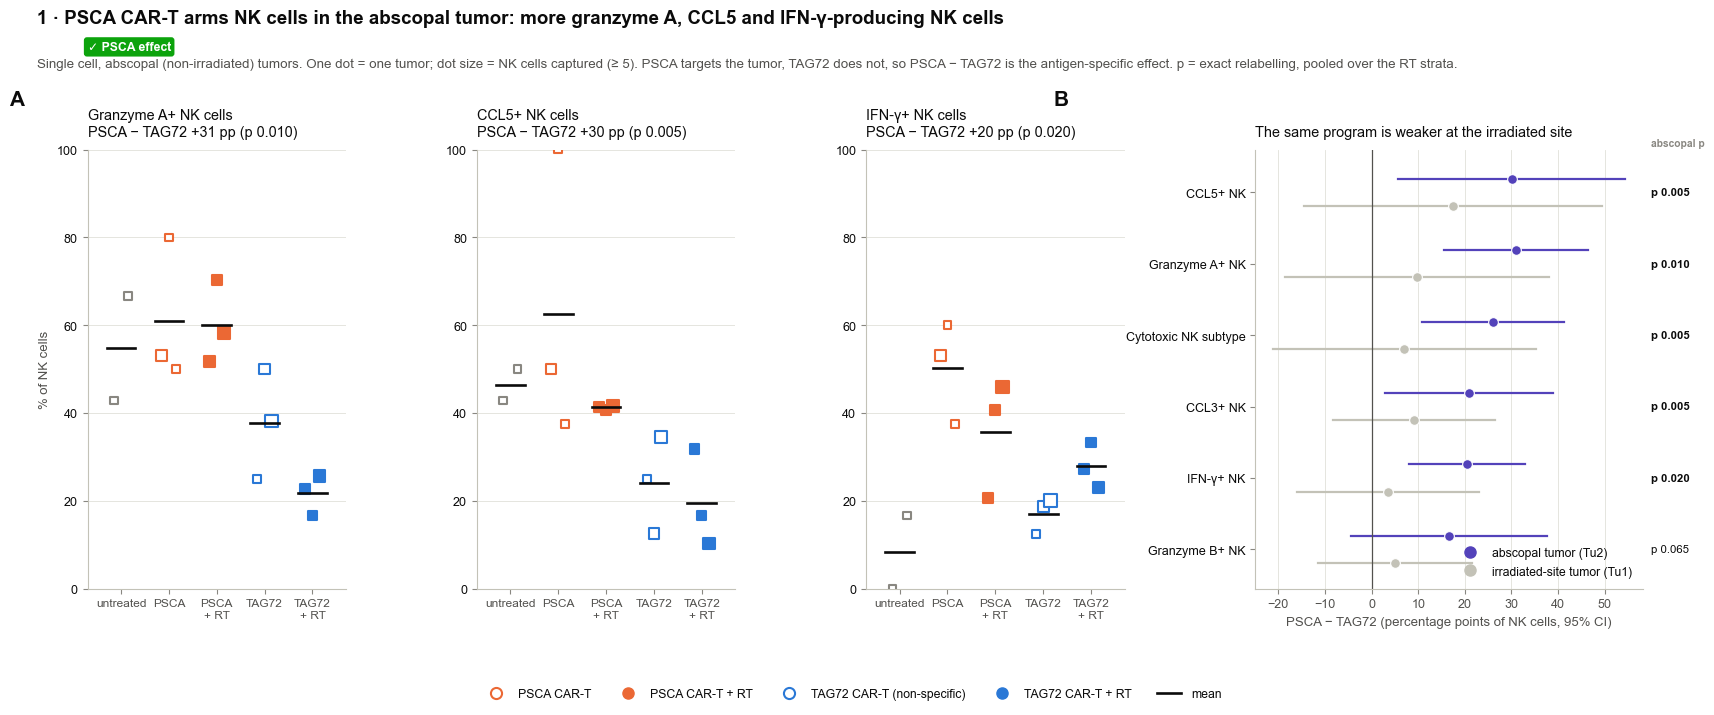

In [3]:
fig = plt.figure(figsize=(17, 7.2))
gs = GridSpec(1, 4, width_ratios=[1, 1, 1, 1.5], wspace=0.45, left=0.05, right=0.965, top=0.78, bottom=0.17)
fig.suptitle("1 · PSCA CAR-T arms NK cells in the abscopal tumor: more granzyme A, CCL5 and IFN-γ-producing NK cells",
             x=0.02, y=0.975, ha="left", fontsize=13.5, weight="bold")
fig.text(0.02, 0.895, "Single cell, abscopal (non-irradiated) tumors. One dot = one tumor; dot size = NK cells captured (≥ 5). "
         "PSCA targets the tumor, TAG72 does not, so PSCA − TAG72 is the antigen-specific effect. p = exact relabelling, "
         "pooled over the RT strata.", fontsize=9.6, color=INK2)
for k, (g_, lab) in enumerate([("Gzma", "Granzyme A+ NK cells"), ("Ccl5", "CCL5+ NK cells"), ("Ifng", "IFN-γ+ NK cells")]):
    ax = fig.add_subplot(gs[k])
    dots(ax, NKF[g_] * 100, NKF[["arm", "site"]], site=2, sizes=NKF["n"], notx=True)
    e = ge(PHENO, f"{g_}+ (% of NK)", "PSCA Tu2", "pooled"); p = ge(PHENO, f"{g_}+ (% of NK)", "PSCA Tu2", "pooled", "p_use")
    ax.set_ylabel("% of NK cells" if k == 0 else None); ax.set_ylim(0, 100)
    ax.set_title(f"{lab}\nPSCA − TAG72 {e:+.0f} pp (p {fmt_p(p)})", loc="left", fontsize=10.4, pad=10)
    if k == 0:
        letter(ax, "A", -0.3, 1.1); badge(ax, "✓ PSCA effect", S_GOOD, x=0.0, y=1.22, ha="left")
ax = fig.add_subplot(gs[3]); letter(ax, "B", -0.52, 1.1)
ROWS = [("Ccl5+ (% of NK)", "CCL5+ NK"), ("Gzma+ (% of NK)", "Granzyme A+ NK"), ("Cytotoxic_NK (% of NK)", "Cytotoxic NK subtype"),
        ("Ccl3+ (% of NK)", "CCL3+ NK"), ("Ifng+ (% of NK)", "IFN-γ+ NK"), ("Gzmb+ (% of NK)", "Granzyme B+ NK")]
rows = []
for ro, lab in ROWS:
    for eff, tag_, col in [("PSCA Tu2", "abscopal", VIOLET), ("PSCA Tu1", "irradiated-site", "#c3c2b7")]:
        d = PHENO[(PHENO.readout == ro) & (PHENO.effect == eff) & (PHENO.part == "pooled")]
        if d.empty: continue
        rows.append((lab, tag_, col, d.est.iloc[0], d.lo.iloc[0], d.hi.iloc[0], d.p_use.iloc[0]))
for i, (lab, tag_, col, est, lo, hi, p) in enumerate(rows):
    y = -(i // 2) + (0.19 if tag_ == "abscopal" else -0.19)
    ax.plot([lo, hi], [y, y], color=col, lw=1.6); ax.plot(est, y, "o", color=col, ms=7, mec="white", mew=0.8, zorder=3)
    if tag_ == "abscopal":
        ax.text(1.02, -(i // 2), f"p {fmt_p(p)}", transform=ax.get_yaxis_transform(), va="center", fontsize=8.2,
                weight="bold" if p < 0.05 else "normal")
ax.axvline(0, color=INK2, lw=0.9); ax.set_yticks([-i for i in range(len(ROWS))]); ax.set_yticklabels([l for _, l in ROWS])
ax.set_ylim(-len(ROWS) + 0.45, 0.6); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_xlabel("PSCA − TAG72 (percentage points of NK cells, 95% CI)")
ax.text(1.02, 0.62, "abscopal p", transform=ax.get_yaxis_transform(), va="bottom", fontsize=7.4, color=MUTED, weight="bold")
ax.set_title("The same program is weaker at the irradiated site", loc="left", fontsize=10.4, pad=10)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=VIOLET, ms=8, label="abscopal tumor (Tu2)"),
                   Line2D([], [], marker="o", ls="", color="#c3c2b7", ms=8, label="irradiated-site tumor (Tu1)")],
          loc="lower right", frameon=False)
fig.legend(handles=LEG[:4] + [LEG[5]], loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, 0.0))
for ext in ("png", "pdf"): fig.savefig(OUT/f"Story1_PSCA_arms_NK.{ext}", bbox_inches="tight")
plt.show()

## Figure 2 — In the irradiated tumor, RT + PSCA lifts the local brake

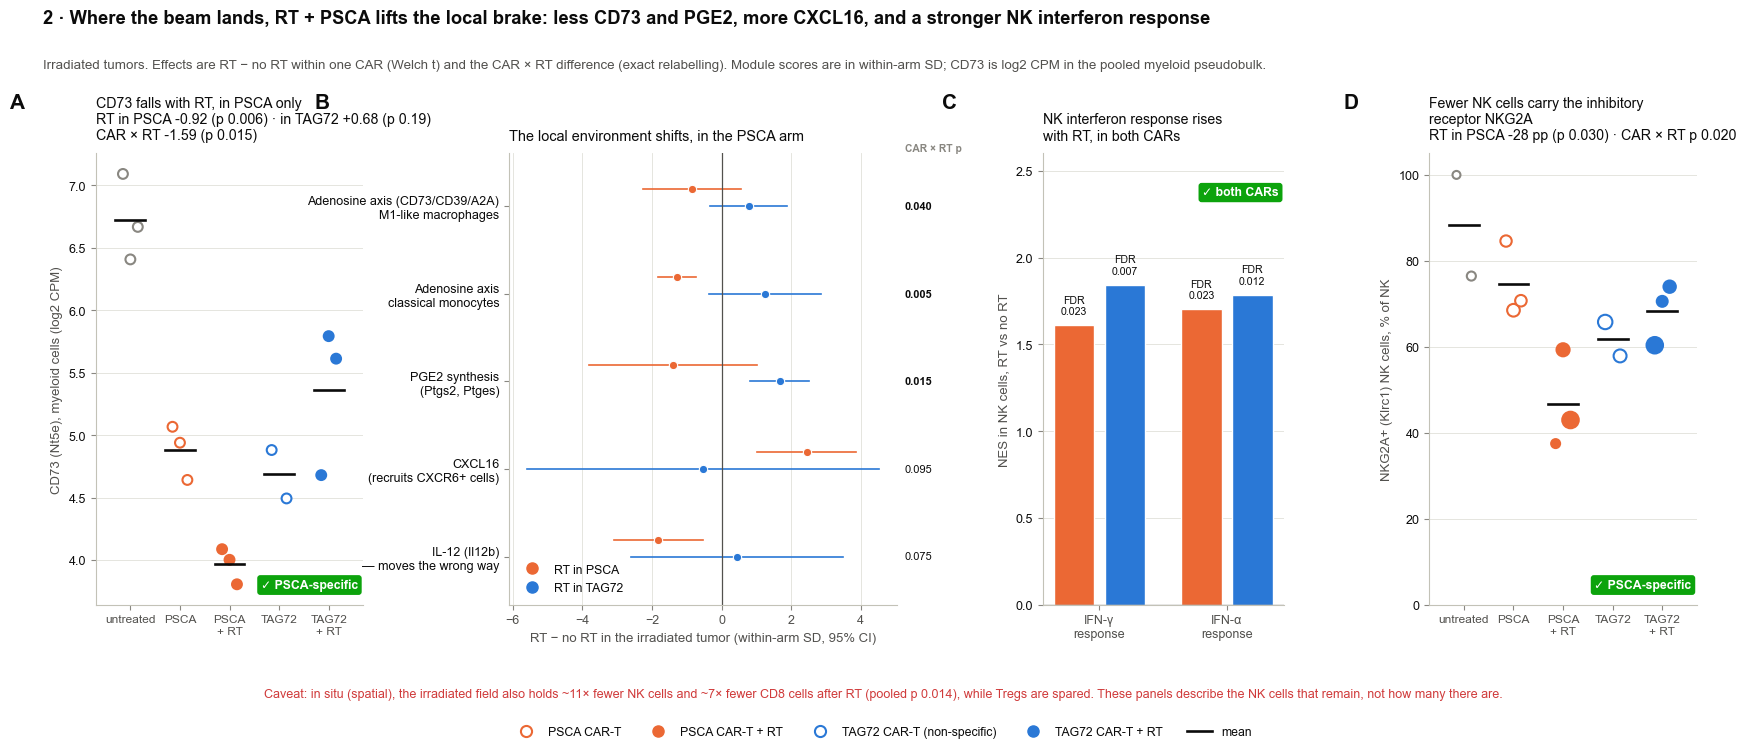

In [4]:
fig = plt.figure(figsize=(17.5, 7.4))
gs = GridSpec(1, 4, width_ratios=[1, 1.45, 0.9, 1], wspace=0.5, left=0.05, right=0.965, top=0.78, bottom=0.17)
fig.suptitle("2 · Where the beam lands, RT + PSCA lifts the local brake: less CD73 and PGE2, more CXCL16, and a stronger NK interferon response",
             x=0.02, y=0.975, ha="left", fontsize=13.2, weight="bold")
fig.text(0.02, 0.895, "Irradiated tumors. Effects are RT − no RT within one CAR (Welch t) and the CAR × RT difference "
         "(exact relabelling). Module scores are in within-arm SD; CD73 is log2 CPM in the pooled myeloid pseudobulk.",
         fontsize=9.6, color=INK2)
ax = fig.add_subplot(gs[0])
dots(ax, CD73, CD73M, site=1, notx=True)
c1 = effect(CD73, CD73M, "RT Tu1")
ax.set_ylabel("CD73 (Nt5e), myeloid cells (log2 CPM)")
ax.set_title(f"CD73 falls with RT, in PSCA only\nRT in PSCA {c1['PSCA']['est']:+.2f} (p {fmt_p(pw(c1['PSCA']))}) · "
             f"in TAG72 {c1['TAG72']['est']:+.2f} (p {fmt_p(pw(c1['TAG72']))})\nCAR × RT {c1['CARxRT']['est']:+.2f} "
             f"(p {fmt_p(c1['CARxRT']['p'])})", loc="left", fontsize=10.2, pad=10)
letter(ax, "A", -0.32, 1.1); badge(ax, "✓ PSCA-specific", S_GOOD, x=0.98, y=0.03)

ax = fig.add_subplot(gs[1]); letter(ax, "B", -0.5, 1.1)
ENVROWS = [("Adenosine axis", MODM, "IFN_stimulated_Mac", "Adenosine axis (CD73/CD39/A2A)\nM1-like macrophages", -1),
           ("Adenosine axis", MODM, "Classical_Mono", "Adenosine axis\nclassical monocytes", -1)]
rows = []
for mod_, df, grp, lab, ori in ENVROWS:
    d = df[(df.module == mod_) & (df.group == grp) & (df.effect == "RT Tu1")].set_index("part")
    if d.empty: continue
    g = lambda k: (d.loc[k, "est"], d.loc[k, "lo"], d.loc[k, "hi"])
    rows.append(dict(label=lab, psca=g("PSCA"), tag=g("TAG72"), pooled=None,
                     p=fmt_p(d.loc["CARxRT", "p"]), bold=d.loc["CARxRT", "p"] < 0.05))
for ro, lab in [("PGE2 synthesis (Ptgs2, Ptges)", "PGE2 synthesis\n(Ptgs2, Ptges)"), ("CXCR6 ligands (Cxcl16)", "CXCL16\n(recruits CXCR6+ cells)"),
                ("IL-12 (Il12b)", "IL-12 (Il12b)\n— moves the wrong way")]:
    d = REC[(REC.readout == ro) & (REC.effect == "RT Tu1")].set_index("part")
    if d.empty: continue
    g = lambda k: (d.loc[k, "est"], d.loc[k, "lo"], d.loc[k, "hi"])
    rows.append(dict(label=lab, psca=g("PSCA"), tag=g("TAG72"), pooled=None,
                     p=fmt_p(d.loc["CARxRT", "p_use"]), bold=d.loc["CARxRT", "p_use"] < 0.05))
forest(ax, rows, "RT − no RT in the irradiated tumor (within-arm SD, 95% CI)", p_head="CAR × RT p")
ax.set_title("The local environment shifts, in the PSCA arm", loc="left", fontsize=10.4, pad=10)
ax.legend(handles=[Line2D([], [], marker="o", ls="", color=C_PSCA, ms=8, label="RT in PSCA"),
                   Line2D([], [], marker="o", ls="", color=C_TAG72, ms=8, label="RT in TAG72")],
          loc="lower left", frameon=False)

ax = fig.add_subplot(gs[2]); letter(ax, "C", -0.42, 1.1)
IFNP = [("HALLMARK_INTERFERON_GAMMA_RESPONSE", "IFN-γ\nresponse"), ("HALLMARK_INTERFERON_ALPHA_RESPONSE", "IFN-α\nresponse")]
for j, (c, col) in enumerate([("RT_in_PSCA", C_PSCA), ("RT_in_TAG72", C_TAG72)]):
    for i, (pth, _) in enumerate(IFNP):
        r = NKGS[(NKGS.site == 1) & (NKGS.contrast == c) & (NKGS.pathway == pth)].iloc[0]
        x = i * 2.5 + j
        ax.bar(x, r.NES, width=0.8, color=col, edgecolor="white")
        ax.text(x, r.NES + 0.05, f"FDR\n{fmt_p(r.FDR)}", ha="center", va="bottom", fontsize=7.6)
ax.set_xticks([0.5, 3.0]); ax.set_xticklabels([p for _, p in IFNP]); ax.axhline(0, color=INK2, lw=0.9)
ax.set_ylabel("NES in NK cells, RT vs no RT"); ax.set_ylim(0, 2.6)
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title("NK interferon response rises\nwith RT, in both CARs", loc="left", fontsize=10.2, pad=10)
badge(ax, "✓ both CARs", S_GOOD, x=0.98, y=0.9)

ax = fig.add_subplot(gs[3]); letter(ax, "D", -0.32, 1.1)
dots(ax, NKF["Klrc1"] * 100, NKF[["arm", "site"]], site=1, sizes=NKF["n"], notx=True)
k1 = effect(NKF["Klrc1"], NKF[["arm", "site"]], "RT Tu1", 100)
ax.set_ylabel("NKG2A+ (Klrc1) NK cells, % of NK"); ax.set_ylim(0, 105)
ax.set_title(f"Fewer NK cells carry the inhibitory\nreceptor NKG2A\nRT in PSCA {k1['PSCA']['est']:+.0f} pp "
             f"(p {fmt_p(pw(k1['PSCA']))}) · CAR × RT p {fmt_p(k1['CARxRT']['p'])}", loc="left", fontsize=10.2, pad=10)
badge(ax, "✓ PSCA-specific", S_GOOD, x=0.98, y=0.03)
ns = effect(np.log2(SPL["NK"] + 0.01), SPL[["arm", "site"]], "RT Tu1")
fig.text(0.5, 0.045, f"Caveat: in situ (spatial), the irradiated field also holds ~{2 ** -ns['PSCA']['est']:.0f}× fewer NK cells "
         f"and ~7× fewer CD8 cells after RT (pooled p {fmt_p(ns['pooled']['p'])}), while Tregs are spared. "
         "These panels describe the NK cells that remain, not how many there are.", ha="center", fontsize=9, color=S_CRIT)
fig.legend(handles=LEG[:4] + [LEG[5]], loc="lower center", ncol=5, frameon=False, bbox_to_anchor=(0.5, -0.025))
for ext in ("png", "pdf"): fig.savefig(OUT/f"Story2_RT_lifts_local_brake.{ext}", bbox_inches="tight")
plt.show()

## Figure 3 — The adenosine machine is a two-cell macrophage relay

Spp1+ among Trem2+ 80% vs 57%; OR 2.91; SPP1-TAM 40% vs 8%


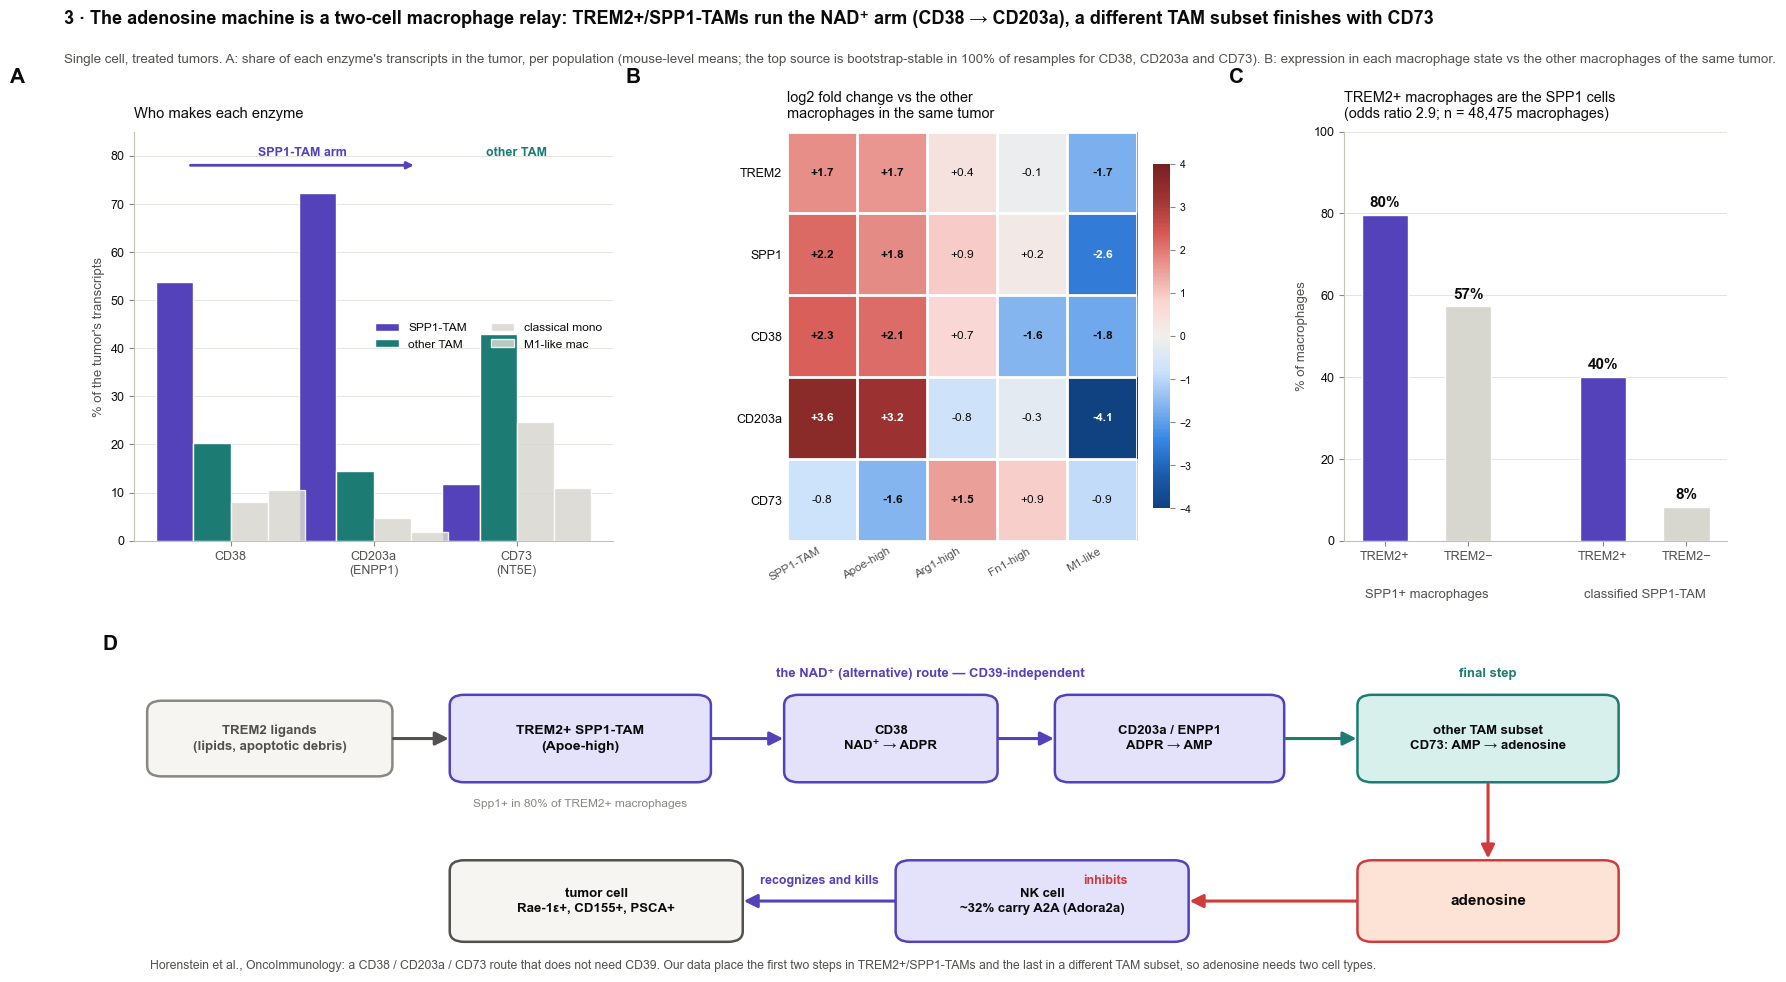

In [5]:
cp = pd.read_parquet(SRC/"cell_panel.parquet", columns=["sample", "arm", "ct2", "ct3", "is_mac", "SPP1_TAM", "Trem2", "Spp1"])
mac = cp[cp.is_mac].copy()
t_pos, s_pos = mac.Trem2 > 0, mac.Spp1 > 0
tab = pd.crosstab(t_pos, s_pos)
OR = (tab.iloc[1, 1] * tab.iloc[0, 0]) / (tab.iloc[1, 0] * tab.iloc[0, 1])
spp1_in_trem2, spp1_in_not = 100 * s_pos[t_pos].mean(), 100 * s_pos[~t_pos].mean()
tam_in_trem2, tam_in_not = 100 * mac.SPP1_TAM[t_pos].mean(), 100 * mac.SPP1_TAM[~t_pos].mean()
print(f"Spp1+ among Trem2+ {spp1_in_trem2:.0f}% vs {spp1_in_not:.0f}%; OR {OR:.2f}; SPP1-TAM {tam_in_trem2:.0f}% vs {tam_in_not:.0f}%")

fig = plt.figure(figsize=(17.5, 10.6))
gs = GridSpec(2, 3, height_ratios=[1, 0.78], width_ratios=[1.25, 1.0, 1.0], hspace=0.3, wspace=0.42,
              left=0.06, right=0.97, top=0.86, bottom=0.07)
fig.suptitle("3 · The adenosine machine is a two-cell macrophage relay: TREM2+/SPP1-TAMs run the NAD⁺ arm (CD38 → CD203a), "
             "a different TAM subset finishes with CD73", x=0.02, y=0.975, ha="left", fontsize=13, weight="bold")
fig.text(0.02, 0.925, "Single cell, treated tumors. A: share of each enzyme's transcripts in the tumor, per population "
         "(mouse-level means; the top source is bootstrap-stable in 100% of resamples for CD38, CD203a and CD73). "
         "B: expression in each macrophage state vs the other macrophages of the same tumor.", fontsize=9.6, color=INK2)
ax = fig.add_subplot(gs[0, 0]); letter(ax, "A", -0.26, 1.12)
POPS = [("SPP1_TAM", "SPP1-TAM"), ("TAM_other", "other TAM"), ("Classical_Mono", "classical mono"),
        ("IFN_stimulated_Mac", "M1-like mac")]
GENES = [("Cd38", "CD38"), ("Enpp1", "CD203a\n(ENPP1)"), ("Nt5e", "CD73\n(NT5E)")]
w = 0.26
for j, (pop, plab) in enumerate(POPS):
    r = POOL[POOL.population == pop]
    if r.empty: continue
    vals = [r[g].iloc[0] * 100 for g, _ in GENES]
    cols = [VIOLET if pop == "SPP1_TAM" else (TEAL if pop == "TAM_other" else "#d7d6cf")] * 3
    ax.bar(np.arange(3) + (j - 1.5) * w, vals, width=w, color=cols, edgecolor="white",
           label=plab, alpha=1.0 if pop in ("SPP1_TAM", "TAM_other") else 0.85)
ax.set_xticks(range(3)); ax.set_xticklabels([l for _, l in GENES]); ax.set_ylabel("% of the tumor's transcripts")
ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True); ax.set_ylim(0, 85)
ax.legend(frameon=False, fontsize=8.6, ncol=2)
ax.set_title("Who makes each enzyme", loc="left", fontsize=10.6, pad=10)
ax.annotate("", xy=(1.3, 78), xytext=(-0.3, 78), arrowprops=dict(arrowstyle="-|>", color=VIOLET, lw=2))
ax.text(0.5, 80, "SPP1-TAM arm", ha="center", fontsize=9, color=VIOLET, weight="bold")
ax.text(2, 80, "other TAM", ha="center", fontsize=9, color=TEAL, weight="bold")

ax = fig.add_subplot(gs[0, 1]); letter(ax, "B", -0.46, 1.12)
ST = [("SPP1_TAM", "SPP1-TAM"), ("Apoe_high_Mac", "Apoe-high"), ("Arg1_high_Mac", "Arg1-high"),
      ("Fn1_high_Mac", "Fn1-high"), ("IFN_stimulated_Mac", "M1-like")]
GG = ["Trem2", "Spp1", "Cd38", "Enpp1", "Nt5e"]
Mx = pd.DataFrame([[STATE[(STATE.state == st) & (STATE.gene == g)].log2FoldChange.squeeze()
                    if len(STATE[(STATE.state == st) & (STATE.gene == g)]) else np.nan for st, _ in ST] for g in GG],
                  index=["TREM2", "SPP1", "CD38", "CD203a", "CD73"], columns=[l for _, l in ST]).astype(float)
im = ax.imshow(Mx.values, cmap=DIVC, norm=mpl.colors.TwoSlopeNorm(vmin=-4, vcenter=0, vmax=4), aspect="auto")
for i in range(Mx.shape[0]):
    for j in range(Mx.shape[1]):
        v = Mx.iat[i, j]
        if np.isfinite(v):
            ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=8.6,
                    color="white" if abs(v) > 2.4 else INK, weight="bold" if abs(v) > 1.5 else "normal")
ax.set_xticks(range(Mx.shape[1])); ax.set_xticklabels(Mx.columns, fontsize=8.4, rotation=30, ha="right")
ax.set_yticks(range(Mx.shape[0])); ax.set_yticklabels(Mx.index)
ax.tick_params(length=0); [sp.set_visible(False) for sp in ax.spines.values()]
ax.set_xticks(np.arange(-.5, Mx.shape[1]), minor=True); ax.set_yticks(np.arange(-.5, Mx.shape[0]), minor=True)
ax.grid(which="minor", color="white", lw=2); ax.tick_params(which="minor", length=0)
ax.set_title("log2 fold change vs the other\nmacrophages in the same tumor", loc="left", fontsize=10.4, pad=10)
cb = fig.colorbar(im, ax=ax, fraction=0.045, pad=0.04); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=7.5)

ax = fig.add_subplot(gs[0, 2]); letter(ax, "C", -0.3, 1.12)
ax.bar([0, 1], [spp1_in_trem2, spp1_in_not], width=0.55, color=[VIOLET, "#d7d6cf"], edgecolor="white")
for x_, v in zip([0, 1], [spp1_in_trem2, spp1_in_not]): ax.text(x_, v + 2, f"{v:.0f}%", ha="center", fontsize=11, weight="bold")
ax.bar([2.6, 3.6], [tam_in_trem2, tam_in_not], width=0.55, color=[VIOLET, "#d7d6cf"], edgecolor="white")
for x_, v in zip([2.6, 3.6], [tam_in_trem2, tam_in_not]): ax.text(x_, v + 2, f"{v:.0f}%", ha="center", fontsize=11, weight="bold")
ax.set_xticks([0, 1, 2.6, 3.6]); ax.set_xticklabels(["TREM2+", "TREM2−", "TREM2+", "TREM2−"], fontsize=9)
ax.text(0.5, -14, "SPP1+ macrophages", ha="center", fontsize=9.4, color=INK2)
ax.text(3.1, -14, "classified SPP1-TAM", ha="center", fontsize=9.4, color=INK2)
ax.set_ylabel("% of macrophages"); ax.set_ylim(0, 100); ax.yaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title(f"TREM2+ macrophages are the SPP1 cells\n(odds ratio {OR:.1f}; n = {len(mac):,} macrophages)",
             loc="left", fontsize=10.4, pad=10)

ax = fig.add_subplot(gs[1, :]); ax.set_xlim(0, 20); ax.set_ylim(0, 5.4); ax.axis("off")
letter(ax, "D", -0.02, 1.0)


def rbox(x, y, w, h, text, fc, ec, fs=10, tc=INK):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04,rounding_size=0.18", fc=fc, ec=ec, lw=1.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc, weight="bold", linespacing=1.3)


def arr(p1, p2, color=INK2, lw=2.2, ls="-"):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=20, color=color, lw=lw, ls=ls, shrinkA=3, shrinkB=3))


rbox(0.2, 3.3, 3.0, 1.2, "TREM2 ligands\n(lipids, apoptotic debris)", "#f6f5f1", MUTED, fs=9.5, tc=INK2)
rbox(4.0, 3.2, 3.2, 1.4, "TREM2+ SPP1-TAM\n(Apoe-high)", "#e4e2fb", VIOLET)
rbox(8.2, 3.2, 2.6, 1.4, "CD38\nNAD⁺ → ADPR", "#e4e2fb", VIOLET, fs=9.5)
rbox(11.6, 3.2, 2.8, 1.4, "CD203a / ENPP1\nADPR → AMP", "#e4e2fb", VIOLET, fs=9.5)
rbox(15.4, 3.2, 3.2, 1.4, "other TAM subset\nCD73: AMP → adenosine", "#d7f0ec", TEAL, fs=9.5)
rbox(15.4, 0.5, 3.2, 1.3, "adenosine", "#fde3d6", S_CRIT, fs=11)
rbox(9.6, 0.5, 3.6, 1.3, "NK cell\n~32% carry A2A (Adora2a)", "#e4e2fb", VIOLET, fs=9.5)
rbox(4.0, 0.5, 3.6, 1.3, "tumor cell\nRae-1ε+, CD155+, PSCA+", "#f6f5f1", INK2, fs=9.5, tc=INK)
arr((3.2, 3.9), (4.0, 3.9)); arr((7.2, 3.9), (8.2, 3.9), VIOLET); arr((10.8, 3.9), (11.6, 3.9), VIOLET)
arr((14.4, 3.9), (15.4, 3.9), TEAL); arr((17.0, 3.2), (17.0, 1.8), S_CRIT)
arr((15.4, 1.15), (13.2, 1.15), S_CRIT); arr((9.6, 1.15), (7.6, 1.15), VIOLET)
ax.text(12.2, 1.45, "inhibits", ha="center", fontsize=9, color=S_CRIT, weight="bold")
ax.text(8.6, 1.45, "recognizes and kills", ha="center", fontsize=9, color=VIOLET, weight="bold")
ax.text(5.6, 2.75, "Spp1+ in 80% of TREM2+ macrophages", ha="center", fontsize=8.6, color=MUTED)
ax.text(10.0, 4.95, "the NAD⁺ (alternative) route — CD39-independent", ha="center", fontsize=9.4, color=VIOLET, weight="bold")
ax.text(17.0, 4.95, "final step", ha="center", fontsize=9.4, color=TEAL, weight="bold")
ax.text(0.2, 0.0, "Horenstein et al., OncoImmunology: a CD38 / CD203a / CD73 route that does not need CD39. Our data place the "
        "first two steps in TREM2+/SPP1-TAMs and the last in a different TAM subset, so adenosine needs two cell types.",
        fontsize=8.8, color=INK2)
for ext in ("png", "pdf"): fig.savefig(OUT/f"Story3_adenosine_relay.{ext}", bbox_inches="tight")
plt.show()

## Figure 4 — The abscopal tumor keeps the brake

NK granule score vs myeloid CD73, within arm x site: rho -0.53, p 0.025, n 23


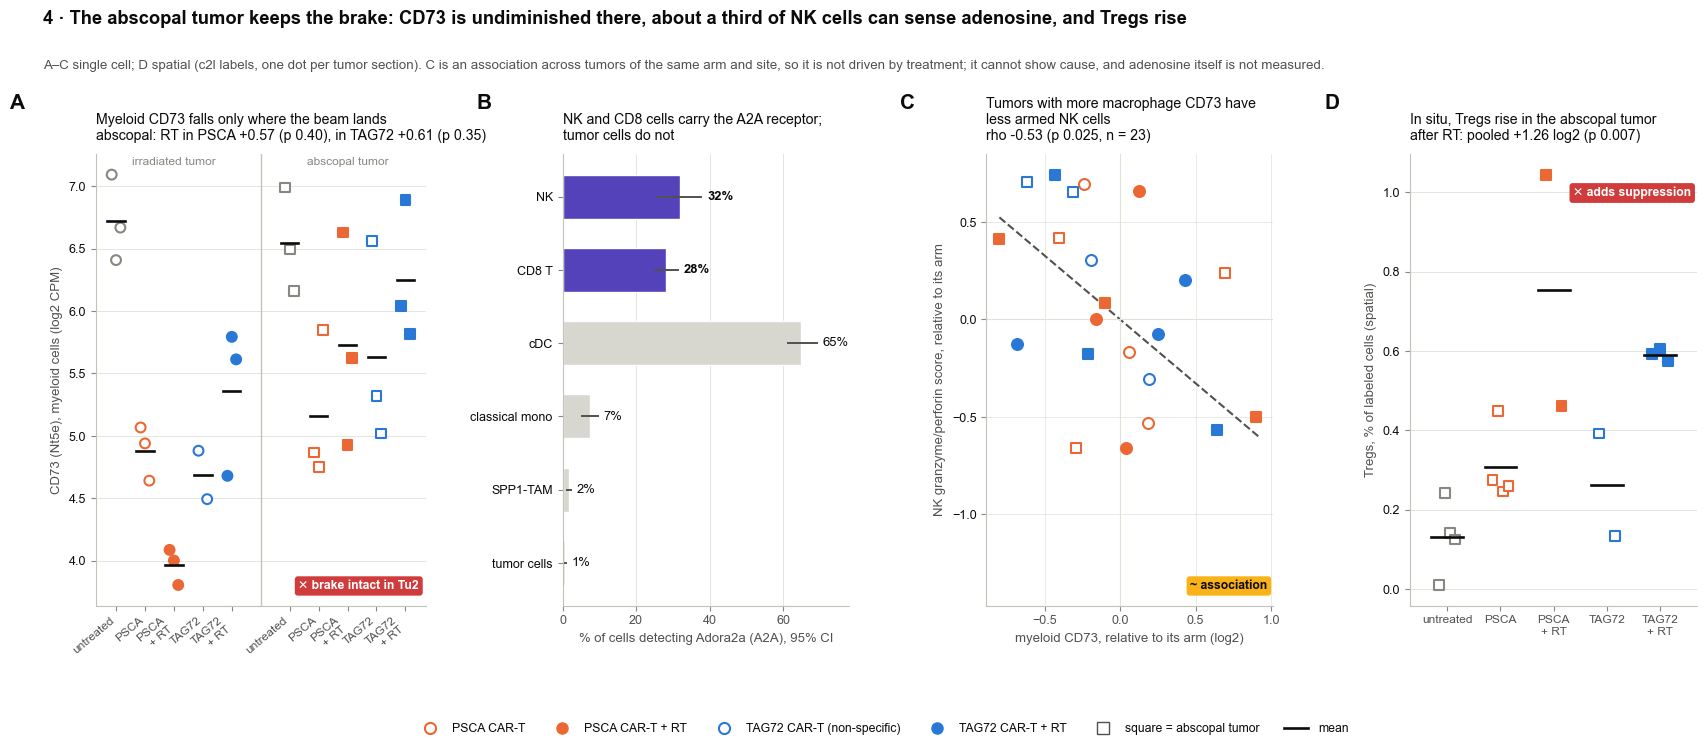

In [6]:
nk5 = PBM[(PBM.group == "NK") & (PBM.n_cells >= 5)]
NK5 = L.loc[nk5.index]; NK5.index = nk5["sample"].values; NK5M = sample_meta(NK5.index)
trm = (NK5M.arm != "NoTx").values
gg = [g for g in ["Gzma", "Gzmb", "Prf1", "Nkg7", "Ctsw"] if g in NK5 and NK5[g].mean() >= 1]
GRAN = ((NK5[gg] - NK5.loc[trm, gg].mean()) / NK5.loc[trm, gg].std()).mean(1)


def within_assoc(y, x, meta, n_perm=5000):
    d = pd.DataFrame({"y": y, "x": x}).join(meta).dropna(); d = d[d.arm.isin(ARMS4)]
    dc = d[["y", "x"]].sub(d.groupby(["arm", "site"])[["y", "x"]].transform("mean"))
    r = stats.spearmanr(dc.y, dc.x).correlation; rng = np.random.default_rng(SEED)
    null = [stats.spearmanr(dc.y, dc.x.groupby([d.arm, d.site]).transform(lambda v: rng.permutation(v.values))).correlation
            for _ in range(n_perm)]
    return r, float((1 + (np.abs(null) >= abs(r)).sum()) / (n_perm + 1)), d, dc


r_gran, p_gran, d_gran, dc_gran = within_assoc(GRAN, CD73, CD73M)
print(f"NK granule score vs myeloid CD73, within arm x site: rho {r_gran:+.2f}, p {p_gran:.3f}, n {len(d_gran)}")

fig = plt.figure(figsize=(17.5, 7.4))
gs = GridSpec(1, 4, width_ratios=[1.15, 1.0, 1.0, 1.0], wspace=0.46, left=0.05, right=0.965, top=0.78, bottom=0.17)
fig.suptitle("4 · The abscopal tumor keeps the brake: CD73 is undiminished there, about a third of NK cells can sense adenosine, "
             "and Tregs rise", x=0.02, y=0.975, ha="left", fontsize=13.2, weight="bold")
fig.text(0.02, 0.895, "A–C single cell; D spatial (c2l labels, one dot per tumor section). C is an association across tumors of the "
         "same arm and site, so it is not driven by treatment; it cannot show cause, and adenosine itself is not measured.",
         fontsize=9.6, color=INK2)
ax = fig.add_subplot(gs[0]); letter(ax, "A", -0.26, 1.1)
dots(ax, CD73, CD73M, notx=True)
c2 = effect(CD73, CD73M, "RT Tu2")
ax.set_ylabel("CD73 (Nt5e), myeloid cells (log2 CPM)")
ax.set_title(f"Myeloid CD73 falls only where the beam lands\nabscopal: RT in PSCA {c2['PSCA']['est']:+.2f} "
             f"(p {fmt_p(pw(c2['PSCA']))}), in TAG72 {c2['TAG72']['est']:+.2f} (p {fmt_p(pw(c2['TAG72']))})",
             loc="left", fontsize=10.2, pad=10)
badge(ax, "✕ brake intact in Tu2", S_CRIT, x=0.98, y=0.03)

ax = fig.add_subplot(gs[1]); letter(ax, "B", -0.3, 1.1)
RD = [("NK", "NK"), ("CD8_T", "CD8 T"), ("cDC", "cDC"), ("Classical_Mono", "classical mono"),
      ("SPP1_TAM", "SPP1-TAM"), ("Cancer_cell", "tumor cells")]
vals, los, his = [], [], []
for pop, _ in RD:
    r = RECDET[RECDET.population == pop]
    vals.append(r.Adora2a_pct.iloc[0]); los.append(r.Adora2a_ci_lo.iloc[0]); his.append(r.Adora2a_ci_hi.iloc[0])
yy = np.arange(len(RD))[::-1]
cols = [VIOLET if p in ("NK", "CD8_T") else "#d7d6cf" for p, _ in RD]
ax.barh(yy, vals, color=cols, height=0.6, edgecolor="white")
for i, (v, lo, hi) in enumerate(zip(vals, los, his)):
    ax.plot([lo, hi], [yy[i]] * 2, color=INK2, lw=1.4)
    ax.text(hi + 1.5, yy[i], f"{v:.0f}%", va="center", fontsize=9.4, weight="bold" if RD[i][0] in ("NK", "CD8_T") else "normal")
ax.set_yticks(yy); ax.set_yticklabels([l for _, l in RD]); ax.set_xlim(0, 78)
ax.set_xlabel("% of cells detecting Adora2a (A2A), 95% CI"); ax.xaxis.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
ax.set_title("NK and CD8 cells carry the A2A receptor;\ntumor cells do not", loc="left", fontsize=10.2, pad=10)

ax = fig.add_subplot(gs[2]); letter(ax, "C", -0.3, 1.1)
dd = dc_gran.join(d_gran[["arm", "site"]])
for _, row in dd.iterrows():
    col_ = CAR_COL[CAR_OF[row.arm]]
    ax.scatter(row.x, row.y, s=62, marker="o" if row.site == 1 else "s", facecolor=col_ if RT_OF[row.arm] else "white",
               edgecolor=col_, lw=1.5, zorder=3)
b1, b0 = np.polyfit(dc_gran.x, dc_gran.y, 1); xx = np.linspace(dc_gran.x.min(), dc_gran.x.max(), 20)
ax.plot(xx, b0 + b1 * xx, color=INK2, lw=1.5, ls="--")
ax.axhline(0, color=GRID, lw=0.8); ax.axvline(0, color=GRID, lw=0.8)
ax.set_xlabel("myeloid CD73, relative to its arm (log2)"); ax.set_ylabel("NK granzyme/perforin score, relative to its arm")
ax.grid(True, color=GRID, lw=0.5); ax.set_axisbelow(True)
ax.set_title(f"Tumors with more macrophage CD73 have\nless armed NK cells\nrho {r_gran:+.2f} (p {fmt_p(p_gran)}, n = {len(d_gran)})",
             loc="left", fontsize=10.2, pad=10)
badge(ax, "~ association", S_WARN, tc=INK, x=0.98, y=0.03)

ax = fig.add_subplot(gs[3]); letter(ax, "D", -0.3, 1.1)
dots(ax, SPL["Treg"], SPL[["arm", "site"]], site=2, notx=True)
tr2 = effect(np.log2(SPL["Treg"] + 0.01), SPL[["arm", "site"]], "RT Tu2")
ax.set_ylabel("Tregs, % of labeled cells (spatial)")
ax.set_title(f"In situ, Tregs rise in the abscopal tumor\nafter RT: pooled {tr2['pooled']['est']:+.2f} log2 "
             f"(p {fmt_p(tr2['pooled']['p'])})", loc="left", fontsize=10.2, pad=10)
badge(ax, "✕ adds suppression", S_CRIT, x=0.98, y=0.9)
fig.legend(handles=LEG, loc="lower center", ncol=6, frameon=False, bbox_to_anchor=(0.5, -0.02))
for ext in ("png", "pdf"): fig.savefig(OUT/f"Story4_abscopal_brake.{ext}", bbox_inches="tight")
plt.show()

## Figure 5 — Model and the proposed experiments

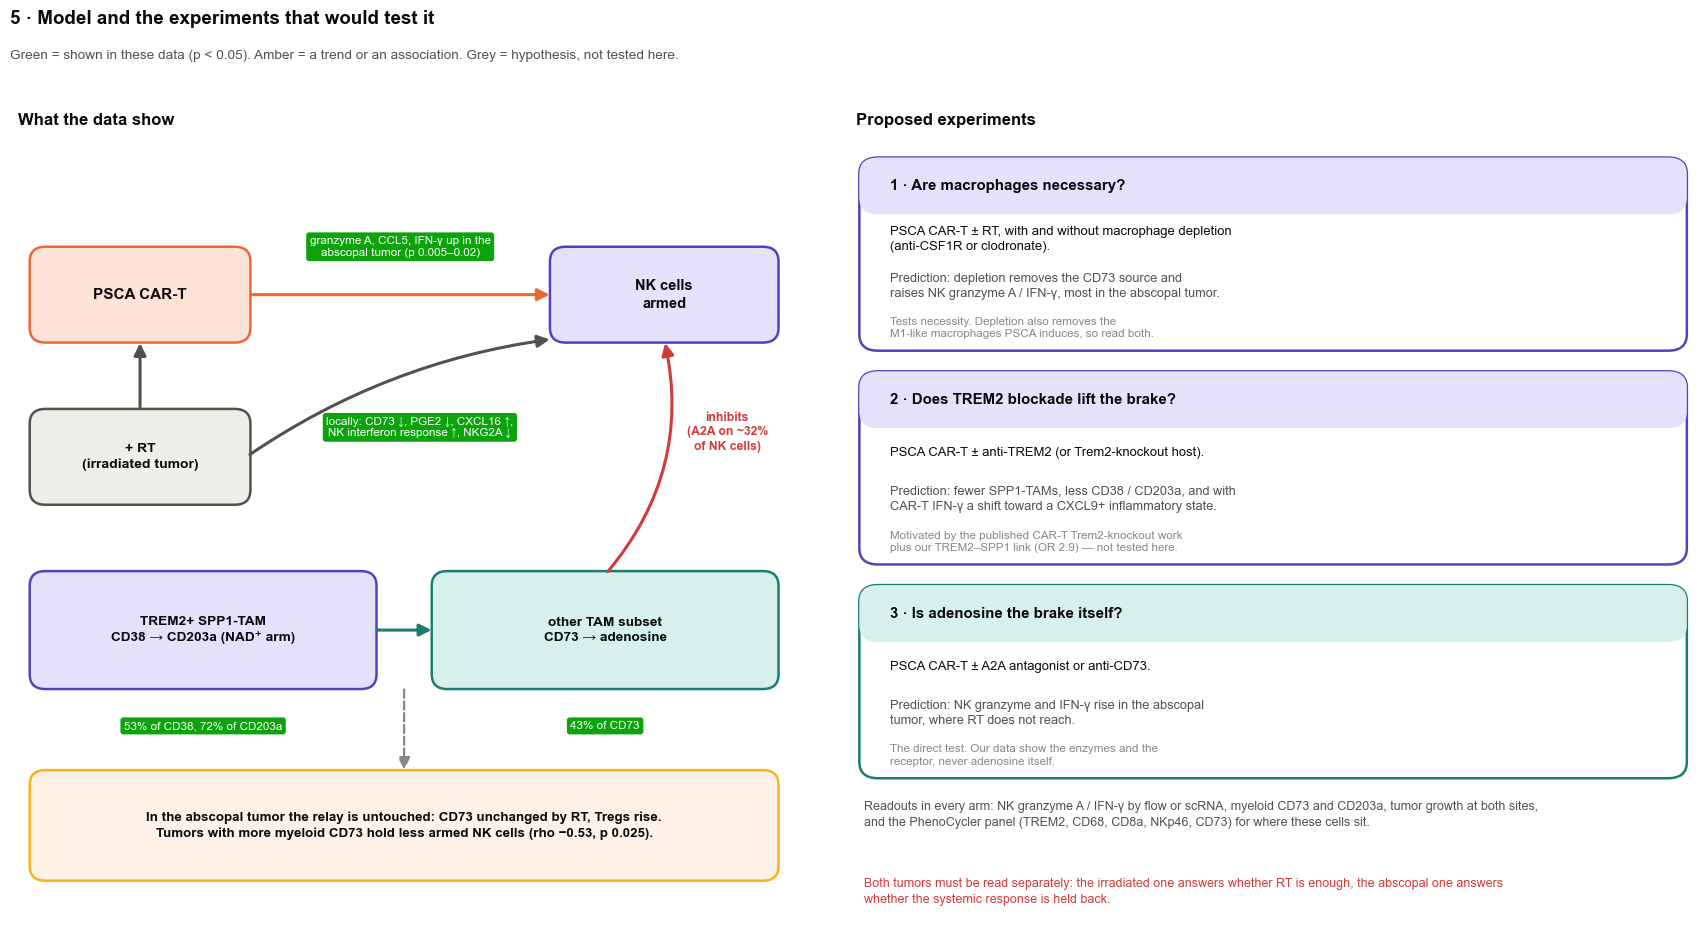


[files] /Users/janzules/Roselab/Spatial/CAR_T/results/rt_advantage/specific_cell_type/story


In [7]:
fig = plt.figure(figsize=(17.5, 9.8))
gs = GridSpec(1, 2, width_ratios=[1.0, 1.08], wspace=0.06, left=0.02, right=0.985, top=0.88, bottom=0.03)
fig.suptitle("5 · Model and the experiments that would test it", x=0.02, y=0.975, ha="left", fontsize=13.5, weight="bold")
fig.text(0.02, 0.925, "Green = shown in these data (p < 0.05). Amber = a trend or an association. Grey = hypothesis, not tested here.",
         fontsize=9.8, color=INK2)
ax = fig.add_subplot(gs[0]); ax.set_xlim(0, 10); ax.set_ylim(0, 11.3); ax.axis("off")
ax.text(0.1, 11.0, "What the data show", fontsize=12, weight="bold")


def mbox(x, y, w, h, text, fc, ec, fs=9.8, tc=INK):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.05,rounding_size=0.2", fc=fc, ec=ec, lw=1.8))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc, weight="bold", linespacing=1.35)


def marr(p1, p2, color=INK2, lw=2.2, ls="-", rad=0.0):
    ax.add_patch(FancyArrowPatch(p1, p2, arrowstyle="-|>", mutation_scale=18, color=color, lw=lw, ls=ls,
                                 connectionstyle=f"arc3,rad={rad}", shrinkA=3, shrinkB=3))


def stag(x, y, text, status, fs=8.4):
    col, tc = {"shown": (S_GOOD, "white"), "trend": (S_WARN, INK), "hyp": ("#d7d6cf", INK2)}[status]
    ax.text(x, y, text, ha="center", va="center", fontsize=fs, color=tc,
            bbox=dict(boxstyle="round,pad=0.3,rounding_size=0.25", fc=col, ec="none"), linespacing=1.2)


mbox(0.3, 8.1, 2.7, 1.2, "PSCA CAR-T", "#fde3d6", C_PSCA, fs=11)
mbox(6.9, 8.1, 2.8, 1.2, "NK cells\narmed", "#e4e2fb", VIOLET, fs=10.5)
marr((3.0, 8.7), (6.9, 8.7), C_PSCA)
stag(4.95, 9.35, "granzyme A, CCL5, IFN-γ up in the\nabscopal tumor (p 0.005–0.02)", "shown")
mbox(0.3, 5.9, 2.7, 1.2, "+ RT\n(irradiated tumor)", "#efeee9", INK2, fs=10)
marr((1.65, 7.1), (1.65, 8.1), INK2)
marr((3.0, 6.5), (6.9, 8.1), INK2, rad=-0.12)
stag(5.2, 6.9, "locally: CD73 ↓, PGE2 ↓, CXCL16 ↑,\nNK interferon response ↑, NKG2A ↓", "shown")
mbox(0.3, 3.4, 4.3, 1.5, "TREM2+ SPP1-TAM\nCD38 → CD203a (NAD⁺ arm)", "#e4e2fb", VIOLET, fs=9.8)
mbox(5.4, 3.4, 4.3, 1.5, "other TAM subset\nCD73 → adenosine", "#d7f0ec", TEAL, fs=9.8)
marr((4.6, 4.15), (5.4, 4.15), TEAL)
stag(2.45, 2.85, "53% of CD38, 72% of CD203a", "shown")
stag(7.55, 2.85, "43% of CD73", "shown")
marr((7.55, 4.9), (8.3, 8.1), S_CRIT, rad=0.25)
ax.text(9.1, 6.6, "inhibits\n(A2A on ~32%\nof NK cells)", ha="center", fontsize=8.8, color=S_CRIT, weight="bold", linespacing=1.25)
mbox(0.3, 0.8, 9.4, 1.4, "In the abscopal tumor the relay is untouched: CD73 unchanged by RT, Tregs rise.\n"
     "Tumors with more myeloid CD73 hold less armed NK cells (rho −0.53, p 0.025).", "#fdf1e8", S_WARN, fs=9.6, tc=INK)
marr((5.0, 3.4), (5.0, 2.2), MUTED, lw=1.6, ls="--")

ax = fig.add_subplot(gs[1]); ax.set_xlim(0, 10); ax.set_ylim(0, 11.3); ax.axis("off")
ax.text(0.1, 11.0, "Proposed experiments", fontsize=12, weight="bold")
EXP = [
    (8.0, "1 · Are macrophages necessary?", "#e4e2fb", VIOLET,
     "PSCA CAR-T ± RT, with and without macrophage depletion\n(anti-CSF1R or clodronate).",
     "Prediction: depletion removes the CD73 source and\nraises NK granzyme A / IFN-γ, most in the abscopal tumor.",
     "Tests necessity. Depletion also removes the\nM1-like macrophages PSCA induces, so read both."),
    (5.1, "2 · Does TREM2 blockade lift the brake?", "#e4e2fb", VIOLET,
     "PSCA CAR-T ± anti-TREM2 (or Trem2-knockout host).",
     "Prediction: fewer SPP1-TAMs, less CD38 / CD203a, and with\nCAR-T IFN-γ a shift toward a CXCL9+ inflammatory state.",
     "Motivated by the published CAR-T Trem2-knockout work\nplus our TREM2–SPP1 link (OR 2.9) — not tested here."),
    (2.2, "3 · Is adenosine the brake itself?", "#d7f0ec", TEAL,
     "PSCA CAR-T ± A2A antagonist or anti-CD73.",
     "Prediction: NK granzyme and IFN-γ rise in the abscopal\ntumor, where RT does not reach.",
     "The direct test. Our data show the enzymes and the\nreceptor, never adenosine itself."),
]
for y, title, fc, ec, design, pred, note in EXP:
    ax.add_patch(FancyBboxPatch((0.2, y), 9.6, 2.5, boxstyle="round,pad=0.06,rounding_size=0.22", fc="white", ec=ec, lw=1.8))
    ax.add_patch(FancyBboxPatch((0.2, y + 1.85), 9.6, 0.65, boxstyle="round,pad=0.06,rounding_size=0.22", fc=fc, ec="none"))
    ax.text(0.5, y + 2.17, title, fontsize=10.8, weight="bold", va="center")
    ax.text(0.5, y + 1.45, design, fontsize=9.4, va="center", color=INK, linespacing=1.3)
    ax.text(0.5, y + 0.82, pred, fontsize=9.2, va="center", color=INK2, linespacing=1.3)
    ax.text(0.5, y + 0.25, note, fontsize=8.4, va="center", color=MUTED, linespacing=1.25)
ax.text(0.2, 1.5, "Readouts in every arm: NK granzyme A / IFN-γ by flow or scRNA, myeloid CD73 and CD203a, tumor growth at "
        "both sites,\nand the PhenoCycler panel (TREM2, CD68, CD8a, NKp46, CD73) for where these cells sit.",
        fontsize=9, color=INK2, linespacing=1.35)
ax.text(0.2, 0.45, "Both tumors must be read separately: the irradiated one answers whether RT is enough, the abscopal one answers\n"
        "whether the systemic response is held back.", fontsize=9, color=S_CRIT, linespacing=1.35)
for ext in ("png", "pdf"): fig.savefig(OUT/f"Story5_model_and_proposal.{ext}", bbox_inches="tight")
plt.show()
print(f"\n[files] {OUT}")